In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!mkdir -p data/raw
!unzip -q "/content/drive/MyDrive/archive.zip" -d data/raw

In [7]:
!mv data/raw/data/* data/raw/
!rmdir data/raw/data
!ls data/raw

Blight	Common_Rust  Gray_Leaf_Spot  Healthy


In [8]:
from pathlib import Path
for d in sorted(Path("data/raw").iterdir()):
    print(d.name, len(list(d.glob("*"))))

Blight 1146
Common_Rust 1306
Gray_Leaf_Spot 574
Healthy 1162


In [9]:
import random
import shutil
from pathlib import Path

RAW = Path("data/raw")
TRAIN = Path("data/train")
TEST = Path("data/test")
SPLIT = 0.8
SEED = 42

def split_dataset():
    random.seed(SEED)
    for class_dir in RAW.iterdir():
        if not class_dir.is_dir():
            continue
        images = sorted(class_dir.glob("*"))
        random.shuffle(images)
        cut = int(len(images) * SPLIT)
        for subset, files in [(TRAIN, images[:cut]), (TEST, images[cut:])]:
            dest = subset / class_dir.name
            dest.mkdir(parents=True, exist_ok=True)
            for f in files:
                shutil.copy(f, dest / f.name)
        print(f"{class_dir.name}: {cut} train, {len(images) - cut} test")

if __name__ == "__main__":
    split_dataset()

Gray_Leaf_Spot: 459 train, 115 test
Healthy: 929 train, 233 test
Common_Rust: 1044 train, 262 test
Blight: 916 train, 230 test


In [10]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "data/train", validation_split=0.2, subset="training",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "data/train", validation_split=0.2, subset="validation",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "data/test", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

Found 3348 files belonging to 4 classes.
Using 2679 files for training.
Found 3348 files belonging to 4 classes.
Using 669 files for validation.
Found 840 files belonging to 4 classes.


In [11]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tensorflow.keras import layers, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)
class_names = train_ds.class_names
print(class_names)

['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


## Visualisation

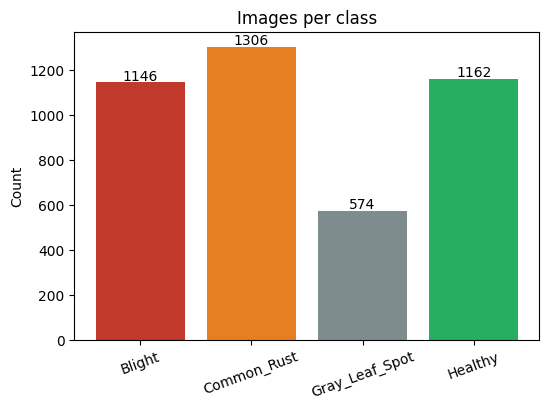

In [12]:
# 1. Class distribution
counts = {c: len(list((RAW/c).glob("*"))) for c in class_names}
plt.figure(figsize=(6,4))
plt.bar(counts.keys(), counts.values(), color=["#c0392b","#e67e22","#7f8c8d","#27ae60"])
for i, v in enumerate(counts.values()):
    plt.text(i, v+10, str(v), ha="center")
plt.title("Images per class"); plt.ylabel("Count"); plt.xticks(rotation=20)
plt.show()

Gray Leaf Spot has about half as many images as the other classes. What that does to its recall is that the model may miss it more often, so we use class weights.

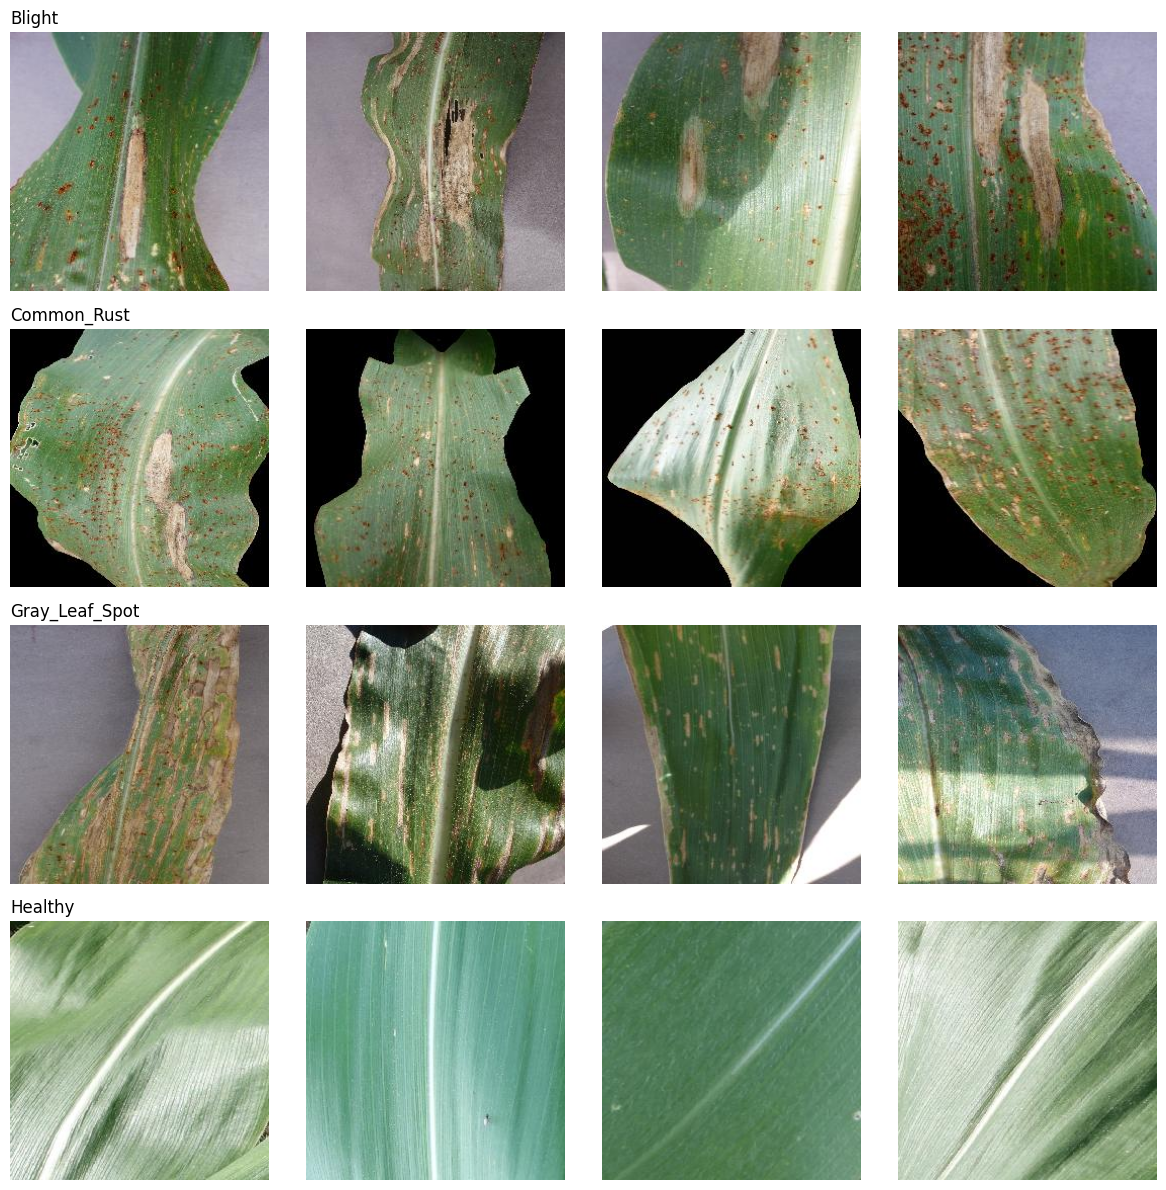

In [13]:
# 2. Sample images per class
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for r, c in enumerate(class_names):
    for k, f in enumerate(random.sample(list((RAW/c).glob("*")), 4)):
        axes[r, k].imshow(Image.open(f)); axes[r, k].axis("off")
        if k == 0: axes[r, k].set_title(c, loc="left")
plt.tight_layout(); plt.show()

All Healthy images are exactly 256×256, while diseased images vary (about 325-380 px). This suggests the classes were collected differently. It likely helps the model separate Healthy (near-perfect score), but field photos may score lower, so Healthy accuracy should be read with caution.

In [14]:
# 3. Image size, brightness and colour statistics (100 images per class)
rows = []
for c in class_names:
    for f in random.sample(list((RAW/c).glob("*")), 100):
        img = Image.open(f).convert("RGB")
        a = np.asarray(img.resize((128,128)), dtype=np.float32)
        rows.append({"class": c, "width": img.size[0], "height": img.size[1],
                     "brightness": a.mean(), "R": a[...,0].mean(),
                     "G": a[...,1].mean(), "B": a[...,2].mean()})
stats = pd.DataFrame(rows)
display(stats.groupby("class")[["width","height","brightness","R","G","B"]].mean().round(1))

,width,height,brightness,R,G,B
class,,,,,,
Blight,378.8,350.9,112.400002,114.699997,123.199997,99.300003
Common_Rust,363.1,355.8,89.900002,94.400002,103.400002,72.000000
Gray_Leaf_Spot,364.6,325.4,112.000000,116.699997,123.500000,95.800003
Healthy,256.0,256.0,137.899994,128.699997,163.000000,122.000000


Healthy leaves are the greenest (G ≈ 163 vs 103-123) and brightest (≈138 vs 72-112). Common Rust is the darkest (≈90) with the lowest blue, consistent with brown rust pustules. Blight and Gray Leaf Spot are nearly identical in brightness and colour, which predicts that a model will confuse them.

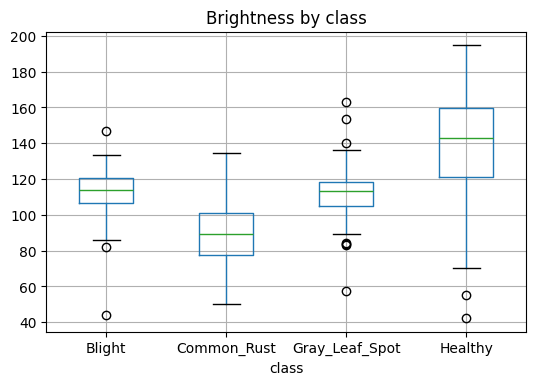

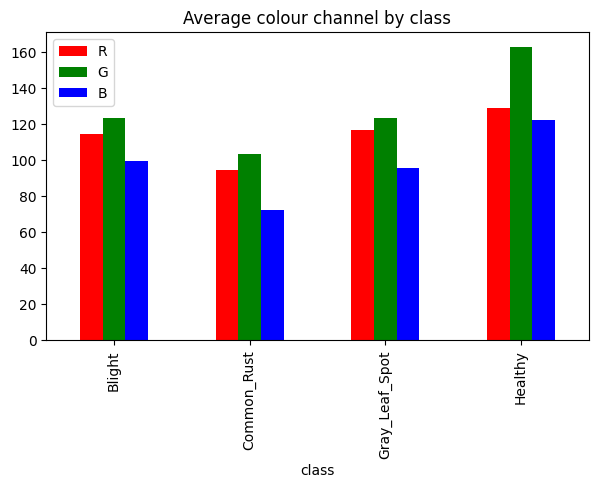

In [15]:
stats.boxplot(column="brightness", by="class", figsize=(6,4))
plt.suptitle(""); plt.title("Brightness by class"); plt.show()

stats.groupby("class")[["R","G","B"]].mean().plot(
    kind="bar", color=["red","green","blue"], figsize=(7,4))
plt.title("Average colour channel by class"); plt.show()

## Preprocessing and class weight

In [16]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

train_counts = [len(list((TRAIN/c).glob("*"))) for c in class_names]
total = sum(train_counts)
class_weight = {i: total/(len(class_names)*n) for i, n in enumerate(train_counts)}
print(class_weight)

{0: 0.9137554585152838, 1: 0.8017241379310345, 2: 1.8235294117647058, 3: 0.9009687836383208}


## Model

In [17]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)])

base = tf.keras.applications.MobileNetV2(
    input_shape=(224,224,3), include_top=False, weights="imagenet")
base.trainable = False

inputs = layers.Input(shape=(224,224,3))
x = augment(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)   # scaling lives inside the model
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Train

In [18]:
es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                      restore_best_weights=True)
history = model.fit(train_ds, validation_data=val_ds, epochs=10,
                    class_weight=class_weight, callbacks=[es])

Epoch 1/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 216s 2s/step - accuracy: 0.7223 - loss: 0.7337 - val_accuracy: 0.8714 - val_loss: 0.3396
Epoch 2/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 179s 2s/step - accuracy: 0.8753 - loss: 0.3768 - val_accuracy: 0.8714 - val_loss: 0.3024
Epoch 3/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 178s 2s/step - accuracy: 0.8843 - loss: 0.3255 - val_accuracy: 0.8879 - val_loss: 0.2604
Epoch 4/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - accuracy: 0.8918 - loss: 0.3137 - val_accuracy: 0.8849 - val_loss: 0.2571
Epoch 5/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 215s 2s/step - accuracy: 0.8906 - loss: 0.2926 - val_accuracy: 0.8834 - val_loss: 0.2679
Epoch 6/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 178s 2s/step - accuracy: 0.9059 - loss: 0.3037 - val_accuracy: 0.8954 - val_loss: 0.2726
Epoch 7/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 178s 2s/step - accuracy: 0.9082 - loss: 0.2696 - val_accuracy: 0.9118 - val_loss: 0.2086
Epoch 8/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - accuracy: 0.9127 - loss: 0.2534 - val_accuracy: 0.9133 - v

## Fine-tune for extra accuracy

In [19]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=5,
                       class_weight=class_weight, callbacks=[es])

Epoch 1/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 212s 2s/step - accuracy: 0.8272 - loss: 0.4793 - val_accuracy: 0.9163 - val_loss: 0.1943
Epoch 2/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 215s 3s/step - accuracy: 0.8761 - loss: 0.3462 - val_accuracy: 0.9133 - val_loss: 0.2142
Epoch 3/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.8992 - loss: 0.2974 - val_accuracy: 0.9013 - val_loss: 0.2349
Epoch 4/5
84/84 ━━━━━━━━━━━━━━━━━━━━ 213s 3s/step - accuracy: 0.9063 - loss: 0.2686 - val_accuracy: 0.8999 - val_loss: 0.2365


## Loss and accuracy curves

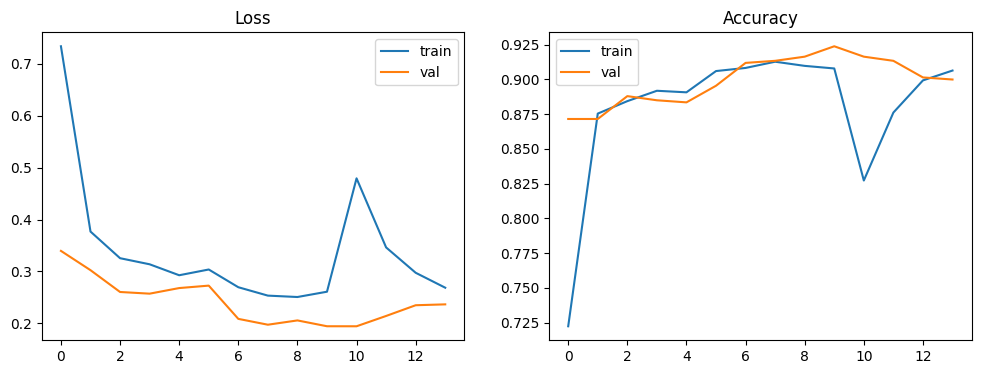

In [20]:
def plot_history(*hs):
    get = lambda k: sum([h.history[k] for h in hs], [])
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    ax[0].plot(get("loss"), label="train"); ax[0].plot(get("val_loss"), label="val")
    ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(get("accuracy"), label="train"); ax[1].plot(get("val_accuracy"), label="val")
    ax[1].set_title("Accuracy"); ax[1].legend()
    plt.show()

plot_history(history, history_ft)   # or plot_history(history)

## Evalution on the test set

27/27 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.9167 - loss: 0.1976
27/27 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step
                precision    recall  f1-score   support

        Blight      0.951     0.761     0.845       230
   Common_Rust      0.962     0.977     0.970       262
Gray_Leaf_Spot      0.677     0.930     0.784       115
       Healthy      1.000     0.996     0.998       233

      accuracy                          0.917       840
     macro avg      0.898     0.916     0.899       840
  weighted avg      0.931     0.917     0.918       840

Accuracy: 0.917 | Macro precision: 0.898 | Macro recall: 0.916 | Macro F1: 0.899 | Test loss: 0.198


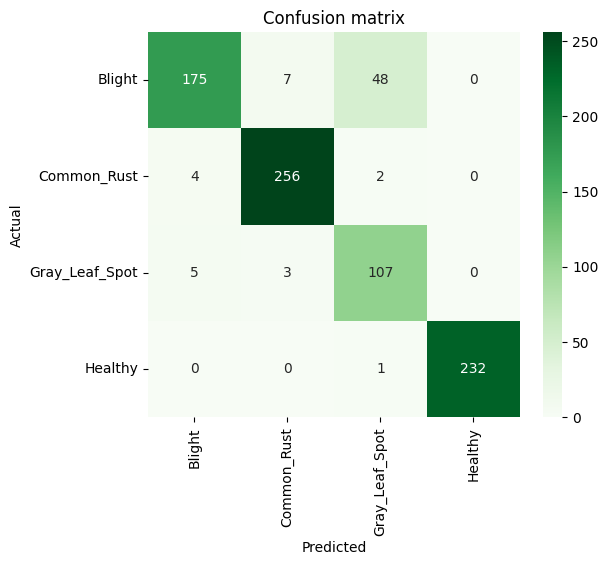

In [21]:
test_loss, test_acc = model.evaluate(test_ds)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = model.predict(test_ds).argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.3f} | Macro precision: {p:.3f} | "
      f"Macro recall: {r:.3f} | Macro F1: {f1:.3f} | Test loss: {test_loss:.3f}")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix"); plt.show()

## Predict function

In [22]:
def predict_image(path):
    img = tf.keras.utils.load_img(path, target_size=(224,224))
    arr = tf.keras.utils.img_to_array(img)[None]
    probs = model.predict(arr, verbose=0)[0]
    i = int(probs.argmax())
    return class_names[i], float(probs[i])

sample = next((TEST/"Blight").glob("*"))
print(predict_image(sample))

('Blight', 0.8513607978820801)


## Saving the model

In [23]:
Path("models").mkdir(exist_ok=True)
model.save("models/maize_model.h5")
json.dump(class_names, open("models/class_names.json", "w"))

## Creating src/ files

In [25]:
from pathlib import Path
Path("src").mkdir(exist_ok=True)

# Writing preprocessing.py programmatically to avoid %%writefile constraints with directory creation
code = """import random, shutil
from pathlib import Path
import tensorflow as tf

def split_dataset(raw=\"data/raw\", train=\"data/train\", test=\"data/test\", split=0.8, seed=42):
    random.seed(seed)
    for class_dir in Path(raw).iterdir():
        if not class_dir.is_dir():
            continue
        images = sorted(class_dir.glob(\"*\"))
        random.shuffle(images)
        cut = int(len(images) * split)
        for subset, files in [(Path(train), images[:cut]), (Path(test), images[cut:])]:
            dest = subset / class_dir.name
            dest.mkdir(parents=True, exist_ok=True)
            for f in files:
                shutil.copy(f, dest / f.name)

def load_datasets(train_dir=\"data/train\", test_dir=\"data/test\", img_size=(224, 224), batch=32):
    kw = dict(image_size=img_size, batch_size=batch)
    train = tf.keras.utils.image_dataset_from_directory(
        train_dir, validation_split=0.2, subset=\"training\", seed=42, **kw)
    val = tf.keras.utils.image_dataset_from_directory(
        train_dir, validation_split=0.2, subset=\"validation\", seed=42, **kw)
    test = tf.keras.utils.image_dataset_from_directory(test_dir, shuffle=False, **kw)
    return train, val, test
"""

with open("src/preprocessing.py", "w") as f:
    f.write(code)
print("Created directory 'src' and wrote 'src/preprocessing.py' successfully!")

Created directory 'src' and wrote 'src/preprocessing.py' successfully!


In [26]:
%%writefile src/model.py
import tensorflow as tf
from tensorflow.keras import layers, models

def build_model(num_classes=4):
    augment = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1), layers.RandomZoom(0.1)])
    base = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = layers.Input(shape=(224, 224, 3))
    x = augment(inputs)
    x = layers.Rescaling(1./127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def train_model(model, train_ds, val_ds, epochs=10, class_weight=None):
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                          restore_best_weights=True)
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     class_weight=class_weight, callbacks=[es])

def retrain(model_path, train_ds, val_ds, epochs=3, save_path=None):
    """Load the saved model, train it further on new data, and save it again."""
    model = tf.keras.models.load_model(model_path)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs)
    model.save(save_path or model_path)
    return history

Writing src/model.py


In [27]:
%%writefile src/prediction.py
import json
import numpy as np
import tensorflow as tf

def load_model(model_path="models/maize_model.h5", classes_path="models/class_names.json"):
    model = tf.keras.models.load_model(model_path)
    class_names = json.load(open(classes_path))
    return model, class_names

def predict_image(model, class_names, image_path):
    img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
    arr = tf.keras.utils.img_to_array(img)[None]
    probs = model.predict(arr, verbose=0)[0]
    i = int(np.argmax(probs))
    return {"class": class_names[i], "confidence": float(probs[i]),
            "probabilities": {c: float(p) for c, p in zip(class_names, probs)}}

Writing src/prediction.py


In [28]:
import sys
sys.path.append("src")
from prediction import load_model as load_saved, predict_image as predict_saved
m, names = load_saved()
print(predict_saved(m, names, str(sample)))

{'class': 'Blight', 'confidence': 0.8513607978820801, 'probabilities': {'Blight': 0.8513607978820801, 'Common_Rust': 0.0009364990401081741, 'Gray_Leaf_Spot': 0.14767572283744812, 'Healthy': 2.6974117645295337e-05}}


In [29]:
!mkdir -p /content/drive/MyDrive/maize_project
!cp -r models src /content/drive/MyDrive/maize_project/
!zip -rq deliverables.zip models src
from google.colab import files
files.download("deliverables.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>